<a href="https://colab.research.google.com/github/silvium76/it-school-project-02/blob/main/Forecasting_proiect_02.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏭 Mini proiect · Senzorul unei mașini industriale

Vei găsi zilele în care o mașină industrială s-a oprit sau s-a defectat, folosind ideile din sesiunea 20: **normalul**, diferența față de normal și un prag de alertă.

Datele sunt măsurători reale, înregistrate la fiecare 5 minute între decembrie 2013 și februarie 2014. Cercetătorii au marcat 4 perioade cu probleme, dar tu vei încerca să le găsești înainte să vezi răspunsul.

**Copie explicată (`_02`): what is new in this copy**

A copy of `Forecasting_proiect.ipynb`. The course text stays in Romanian; everything added is in English:
- **every `# ...` blank filled in** (marked SOLVED), with an **English comment under every line of code** and a **"What this cell does"** note after every code cell, with the real numbers of this run;
- the questions of Pasul 9 answered in "Răspunsurile tale";
- extras to check the answers:
  - one picture with the raw data, the daily mean, the baseline, the real failure periods and the flagged days;
  - the 10% / 20% / 40% thresholds;
  - the "same weekday last week" baseline;
  - a bar chart of the daily differences;
  - an **explained confusion matrix, day by day**.

This is the same machine-temperature exercise as the homework at the end of Session 21 (where the notebook was titled "Sesiunea 20"), so the numbers match the course solution. Runs in a few seconds; it downloads one ~1 MB CSV.

## Cum rulezi în Google Colab

1. Deschide notebook-ul în Google Colab.
2. Rulează celulele pe rând, de sus în jos, folosind butonul ▶️ din stânga celulei.
3. La celulele cu `# ...`, completează codul după indicația din comentariu, apoi rulează celula.
4. Uită-te la grafic după fiecare pas și notează observațiile în celulele de răspuns.

In [1]:
# Importăm bibliotecile de care avem nevoie.
# (the course's comment) the libraries we need
# pandas = citim și prelucrăm tabelul; matplotlib = desenăm grafice.
# (the course's comment) pandas reads and processes the table; matplotlib draws charts
import pandas as pd
# tables and time series
import matplotlib.pyplot as plt
# charts

**What this cell does:**
- Imports pandas and matplotlib: everything this project needs.

## Misiunea

Un senzor măsoară temperatura unei mașini industriale mari. În perioada analizată, mașina s-a oprit sau s-a defectat de 4 ori.

**Obiectiv:** găsește zilele cu probleme folosind un prag de scădere mai mare de 20% față de temperatura tipică din zilele anterioare.

### Pasul 1 · Încarcă datele

URL-ul este deja pregătit. Citește fișierul CSV într-un DataFrame numit `masina` și afișează primele rânduri.

In [2]:
URL = "https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/machine_temperature_system_failure.csv"
# the NAB (Numenta Anomaly Benchmark) file: a large industrial machine's temperature, every 5 minutes
masina = pd.read_csv(URL)   # (citește CSV-ul de la URL)
# SOLVED (was `# ...`): read the CSV straight from the internet into a DataFrame ("mașina" = the machine)
masina.head()
# the first 5 rows

,timestamp,value
0,2013-12-02 21:15:00,73.967322
1,2013-12-02 21:20:00,74.935882
2,2013-12-02 21:25:00,76.124162
3,2013-12-02 21:30:00,78.140707
4,2013-12-02 21:35:00,79.329836


**What this cell does:**
- **22,695 measurements**, one every 5 minutes, from **2 Dec 2013 21:15 to 19 Feb 2014 15:25**. Two columns: `timestamp` (still plain text) and `value` (the temperature; the unit is not given).

### Pasul 2 · Pregătește timpul

Transformă coloana `timestamp` în dată și folosește-o ca index. Astfel, pandas va putea grupa măsurătorile pe zile.

In [3]:
masina["timestamp"] = pd.to_datetime(masina["timestamp"])
# SOLVED: the timestamp column is text ("2013-12-02 21:15:00") → real dates pandas can calculate with
masina = masina.set_index("timestamp")
# SOLVED: the dates become the index (the row labels) → resample, rolling and date slicing work by time

**What this cell does:**
- Turns the text dates into `datetime` values and makes them the index: a **time series**. Same as the taxi data in Session 21.

### Pasul 3 · Privește măsurătorile

Desenează coloana `value`. Observi deja o zonă în care temperatura scade brusc?

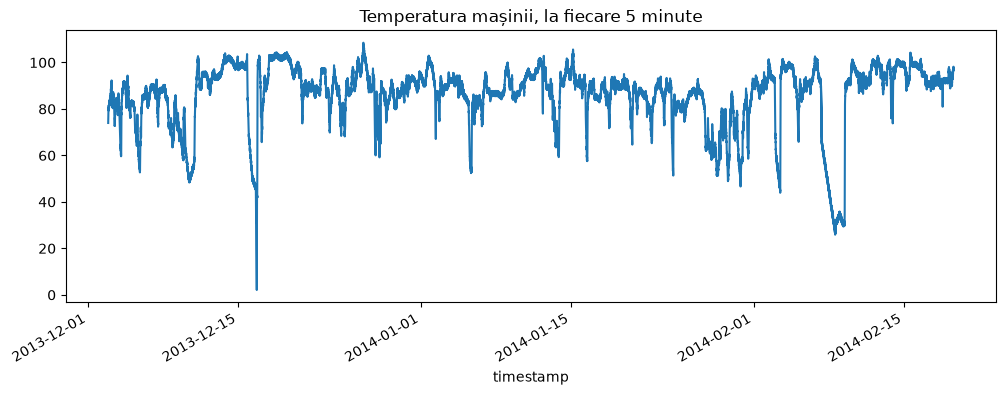

In [4]:
# ✏️ Desenează coloana "value" și afișează graficul.
# (the course's task) draw the "value" column and show the chart
masina["value"].plot(figsize=(12, 4), title="Temperatura mașinii, la fiecare 5 minute")
# SOLVED: one line through all the measurements; pandas puts the dates on the x axis because they are the index
plt.show()
# show the chart

**What this cell does:**
- Most of the time the temperature sits around **80–100** (median 89.4). There are sharp dips:
  - around **10 Dec** and **16 Dec**, where the lowest point of the whole file, **2.1**, is reached on 16 Dec at 17:25;
  - around **28 Jan**;
  - a long, deep dip around **7–9 Feb**.
- With 288 points per day the chart is very noisy, which is why the next step averages per day.

### Pasul 4 · Calculează media pe zi

La taxiuri am adunat pasagerii cu `sum`. Pentru temperatură, adunarea nu are sens: calculăm media zilnică folosind `mean`.

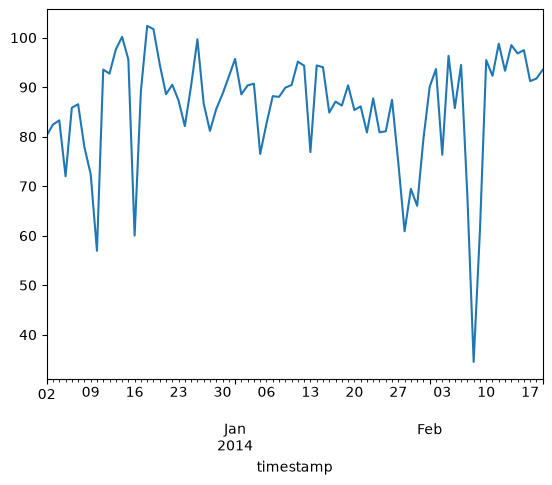

In [5]:
pe_zi_m = masina["value"].resample("D").mean()   # (media valorilor pentru fiecare zi)
# SOLVED: resample("D") groups the 5-minute rows by calendar day, .mean() averages each day → one value per day ("pe zi" = per day)
pe_zi_m.plot()
# the daily series
plt.show()
# show it

**What this cell does:**
- 80 daily values, none missing. The dips are now clear:
  - **10 Dec: 56.9** (vs ~72–93 around it);
  - **16 Dec: 60.0** (vs ~95–100);
  - a drop on **28 Jan**;
  - the lowest daily mean, **34.5, on 8 Feb**.
- `mean`, not `sum`: adding 288 temperatures makes no sense. And a day with missing measurements would get a lower sum without being colder.

### Pasul 5 · Definește ce înseamnă „tipic”

Mașina nu are weekend, deci folosim **mediana ultimelor 7 zile**, fără ziua de azi. Codul este deja scris: citește-l și observă ce face `.rolling(7).median().shift(1)`.

In [6]:
tipic_m = pe_zi_m.rolling(7).median().shift(1)
# rolling(7).median() = the median of a moving window of 7 days (today + the 6 before); .shift(1) moves it one day forward, so each day is compared with the 7 days BEFORE it, not including itself ("tipic" = typical)

**What this cell does:**
- Defines "**normal**" for each day: the **median of the 7 previous days**.
  - **Median**, not mean, so that one broken day does not drag "normal" down for the next week.
  - **`shift(1)`** so that today's value is not part of its own baseline. Otherwise a sudden drop would partly hide itself.
- The first 7 days have no full history, so they are `NaN` and cannot be judged.

### Pasul 6 · Calculează diferența în procente

Compară valoarea reală cu valoarea tipică. Formula este: `(real - tipic) / tipic`.

In [7]:
diferenta_m = (pe_zi_m - tipic_m) / tipic_m   # (real minus tipic, împărțit la tipic)
# SOLVED: the relative difference: −0.25 means 25% colder than typical ("diferență" = difference)

**What this cell does:**
- The difference **in percent of normal**, so the threshold means the same at any temperature level. Negative = colder than usual, which is what happens when the machine stops or breaks.

### Pasul 7 · Selectează zilele cu probleme

Ne interesează o scădere mai mare de 20%. În acest caz, diferența este mai mică decât `-0.20`.

In [8]:
probleme = diferenta_m[diferenta_m < -0.20]   # (indiciu: diferenta_m < -0.20)
# SOLVED: boolean filter → keep only the days more than 20% colder than typical ("probleme" = problems)
probleme.round(2)
# show them with 2 decimals

timestamp
2013-12-10   -0.31
2013-12-16   -0.36
2014-01-28   -0.25
2014-02-07   -0.25
2014-02-08   -0.62
2014-02-09   -0.29
Name: value, dtype: float64

**What this cell does:**
- **6 days** are more than 20% below typical:
  - **10 Dec (−31%)**
  - **16 Dec (−36%)**
  - **28 Jan (−25%)**
  - **7 Feb (−25%), 8 Feb (−62%), 9 Feb (−29%)**

### Pasul 8 · Compară cu perioadele reale

Cercetătorii NAB au marcat următoarele 4 perioade cu probleme reale. Compară-le cu zilele găsite de tine.

In [9]:
perioade_reale = [
    "10–11 decembrie 2013",
    "16–17 decembrie 2013",
    "28 ianuarie 2014",
    "7–9 februarie 2014",
]
# the 4 failure periods marked by the NAB researchers ("perioade reale" = real periods)
perioade_reale
# show the list

['10–11 decembrie 2013',
 '16–17 decembrie 2013',
 '28 ianuarie 2014',
 '7–9 februarie 2014']

**What this cell does:**
- Every flagged day falls inside a real period, and **every one of the 4 periods has at least one flagged day: 4 of 4 found, with no false alarm.**
- Not flagged: **11 Dec and 17 Dec**, the second day of the first two periods. The failures happened on the 10th and the 16th, and the next day's daily **mean** was already back near normal (93.5 and 89.2).

**Extra (this copy) · checking the answers: a picture, three thresholds, the "same weekday" idea, and an explained confusion matrix**

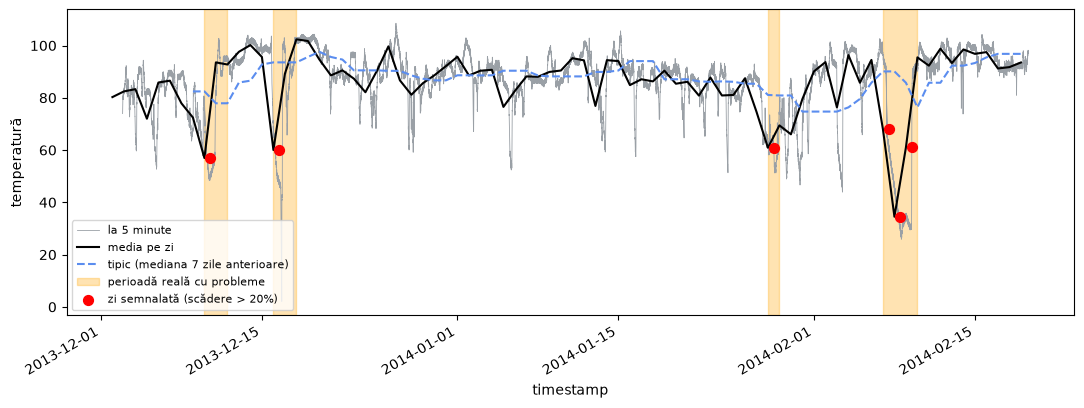

In [10]:
reale = [("2013-12-10", "2013-12-11"), ("2013-12-16", "2013-12-17"), ("2014-01-28", "2014-01-28"), ("2014-02-07", "2014-02-09")]
# the 4 real periods as (first day, last day)

ax = masina["value"].plot(figsize=(13, 4.5), color="#9aa0a6", lw=0.6, label="la 5 minute")
# the raw measurements, thin and grey
pe_zi_m.plot(ax=ax, color="black", lw=1.5, label="media pe zi")
# the daily mean, on top
tipic_m.plot(ax=ax, color="#5b8def", lw=1.5, ls="--", label="tipic (mediana 7 zile anterioare)")
# the baseline it is compared with
for k, (a, b) in enumerate(reale):
    # shade the real failure periods
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color="orange", alpha=0.3,
               label="perioadă reală cu probleme" if k == 0 else None)
    # orange band from the start of the first day to the end of the last; legend only once
ax.scatter(probleme.index + pd.Timedelta(hours=12), pe_zi_m[probleme.index], color="red", zorder=5, s=50,
           label="zi semnalată (scădere > 20%)")
# red dots on the flagged days (placed at midday)
ax.set_ylabel("temperatură"); ax.legend(loc="lower left", fontsize=8)
# labels
plt.show()
# draw

**What this cell does:**
- Grey = every 5 minutes, black = the daily mean, blue dashed = "typical" (the 7-day median before each day), orange = the NAB failure periods, red = our flagged days.
- All red dots sit inside orange bands. The blue line reacts **slowly**, which is the point: a single bad day barely moves a median.
- After the February failure the median dips for a few days, so the following days are compared with a lower "normal". Still no false alarm here.

In [11]:
def cate_gasite(zile):
    # how many of the 4 real periods contain at least one flagged day ("câte găsite" = how many found)
    return sum(any(pd.Timestamp(a) <= z <= pd.Timestamp(b) for z in zile) for a, b in reale)
for prag in [0.10, 0.20, 0.40]:
    # question 2: three thresholds ("prag" = threshold)
    zile = diferenta_m[diferenta_m < -prag].index
    # the flagged days for this threshold
    print(f"scădere > {prag:.0%}: {len(zile):2d} zile semnalate, {cate_gasite(zile)} din 4 perioade găsite -> {[str(z.date()) for z in zile]}")
    # how many days, how many real periods, which days
dif_sapt = (pe_zi_m - pe_zi_m.shift(7)) / pe_zi_m.shift(7)
# question 3: "typical" = the same weekday one week earlier, as for the taxis ("săpt" = week)
zile = dif_sapt[dif_sapt < -0.20].index
# flagged with that baseline
print(f"\n'aceeași zi de acum o săptămână': {len(zile)} zile, {cate_gasite(zile)} din 4 perioade -> {[str(z.date()) for z in zile]}")
# compare with the 7-day median

scădere > 10%: 12 zile semnalate, 4 din 4 perioade găsite -> ['2013-12-09', '2013-12-10', '2013-12-16', '2014-01-05', '2014-01-13', '2014-01-27', '2014-01-28', '2014-01-29', '2014-01-30', '2014-02-07', '2014-02-08', '2014-02-09']
scădere > 20%:  6 zile semnalate, 4 din 4 perioade găsite -> ['2013-12-10', '2013-12-16', '2014-01-28', '2014-02-07', '2014-02-08', '2014-02-09']
scădere > 40%:  1 zile semnalate, 1 din 4 perioade găsite -> ['2014-02-08']

'aceeași zi de acum o săptămână': 5 zile, 3 din 4 perioade -> ['2013-12-10', '2014-01-28', '2014-01-30', '2014-02-08', '2014-02-09']


**What this cell does:**
- Question 2 in numbers:
  - **10%:** 12 days flagged, 4 of 4 periods found, but with **6 false alarms** (9 Dec, 5 Jan, 13 Jan, 27/29/30 Jan).
  - **20%:** 6 days, 4 of 4, **0 false alarms**.
  - **40%:** only **8 Feb**, so 1 of 4 periods.
- The threshold is the classic trade-off from Session 6: lower = catch everything but cry wolf; higher = quiet but miss failures.
- **Question 3:** with "the same day last week" as normal, the rule finds only **3 of 4** periods. **16 Dec is missed**, because 9 Dec, a week earlier, was itself a low day (72.5), so 16 Dec did not look unusual. It also raises a false alarm on 30 Jan.
- A machine has no weekly rhythm, so one comparison day is a fragile baseline. A **median of 7 days** is robust to one bad day.

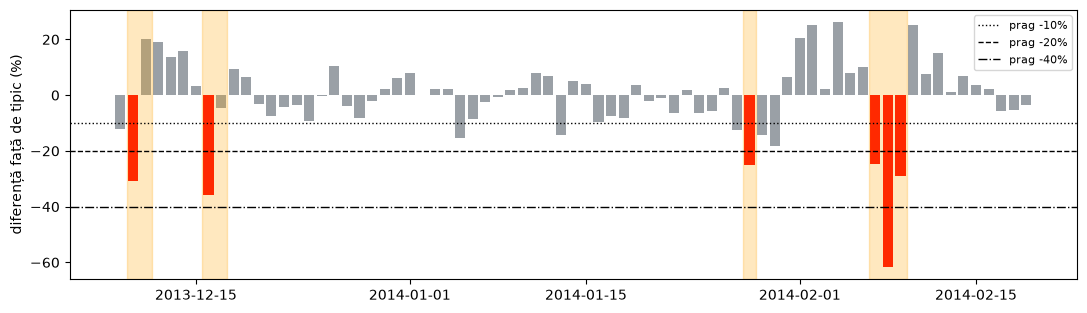

In [12]:
fig, ax = plt.subplots(figsize=(13, 3.5))
# one chart
ax.bar(diferenta_m.index, diferenta_m * 100, color=["red" if v < -0.20 else "#9aa0a6" for v in diferenta_m.fillna(0)])
# one bar per day: the difference from typical in %; red when below −20%
for prag, stil in [(-10, ":"), (-20, "--"), (-40, "-.")]:
    ax.axhline(prag, color="black", ls=stil, lw=1, label=f"prag {prag}%")
    # the three thresholds of question 2
for a, b in reale:
    ax.axvspan(pd.Timestamp(a) - pd.Timedelta(hours=12), pd.Timestamp(b) + pd.Timedelta(hours=12), color="orange", alpha=0.25)
    # the real periods again
ax.set_ylabel("diferență față de tipic (%)"); ax.legend(fontsize=8)
# labels
plt.show()
# draw

**What this cell does:**
- Each bar is one day's difference from typical. The red bars (below −20%) are exactly the 6 flagged days, all inside the orange periods.
- The −10% line is crossed by several grey bars outside the orange bands: the false alarms of the 10% threshold. Only the 8 Feb bar reaches −40% (−62%).
- The tall positive bars after failures (+20–26%) are the machine coming back to its normal heat while the "typical" baseline is still low.

In [13]:
def matrice_confuzie_explicata(y_true, y_pred, pozitiv="pozitiv", negativ="negativ", titlu="Matricea de confuzie"):
    # draws a 2x2 confusion matrix with the definition written inside every square and the metrics around it
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    # turn the inputs into numpy arrays so they can be compared element by element
    TP = int(((y_true == 1) & (y_pred == 1)).sum())
    # True Positive: really positive, predicted positive
    FN = int(((y_true == 1) & (y_pred == 0)).sum())
    # False Negative: really positive, predicted negative (a missed positive)
    FP = int(((y_true == 0) & (y_pred == 1)).sum())
    # False Positive: really negative, predicted positive (a false alarm)
    TN = int(((y_true == 0) & (y_pred == 0)).sum())
    # True Negative: really negative, predicted negative
    total = TP + FN + FP + TN
    # number of predictions

    fig, ax = plt.subplots(figsize=(10, 6))
    # one empty drawing area
    patrate = [(0, 0, TP, "True Positives (TP)", f"real {pozitiv} → prezis {pozitiv}", True),
               (0, 1, FN, "False Negatives (FN)", f"real {pozitiv} → prezis {negativ}", False),
               (1, 0, FP, "False Positives (FP)", f"real {negativ} → prezis {pozitiv}", False),
               (1, 1, TN, "True Negatives (TN)", f"real {negativ} → prezis {negativ}", True)]
    # the 4 squares: (row, column, count, name, meaning, correct?); rows = reality, columns = prediction
    for rand, col, n, nume, sens, corect in patrate:
        # draw each square ("rând" = row)
        ax.add_patch(plt.Rectangle((col, 1 - rand), 1, 1, facecolor="#5b8def" if corect else "#ebe6f0", edgecolor="white", lw=4))
        # blue = correct predictions (the diagonal), light grey = mistakes
        culoare = "white" if corect else "#333333"
        # text colour that stays readable on the square ("culoare" = colour)
        ax.text(col + .5, 1 - rand + .62, f"{n:,}", ha="center", va="center", fontsize=20, fontweight="bold", color=culoare)
        # the count, big
        ax.text(col + .5, 1 - rand + .38, nume, ha="center", va="center", fontsize=12, color=culoare)
        # the definition, e.g. "False Negatives (FN)"
        ax.text(col + .5, 1 - rand + .2, sens, ha="center", va="center", fontsize=9.5, color=culoare, style="italic")
        # what it means in words

    for col, eticheta in [(0, pozitiv), (1, negativ)]:
        # column headers = the prediction ("etichetă" = label)
        ax.text(col + .5, 2.08, eticheta, ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax.text(1, 2.32, "Predicted value (ce spune modelul)", ha="center", va="bottom", fontsize=12)
    # title of the columns
    for rand, eticheta in [(0, pozitiv), (1, negativ)]:
        # row headers = the reality
        ax.text(-.05, 1 - rand + .5, eticheta, ha="right", va="center", fontsize=12, fontweight="bold")
    ax.text(-.55, 1, "Actual value (realitate)", ha="center", va="center", fontsize=12, rotation=90)
    # title of the rows

    def fractie(a, b):
        # safe division: returns 0 instead of crashing when the denominator is 0
        return a / b if b else 0.0
    mici = dict(fontsize=10, va="center")
    # shared text style for the metrics around the matrix
    ax.text(2.06, 1.5, f"Recall (sensitivity)\n= TP / (TP + FN) = {fractie(TP, TP + FN):.3f}", ha="left", **mici)
    # right of the positive row: share of real positives that were caught
    ax.text(2.06, .5, f"Specificity\n= TN / (TN + FP) = {fractie(TN, TN + FP):.3f}", ha="left", **mici)
    # right of the negative row: share of real negatives recognised as negative
    ax.text(.5, -.2, f"Precision\n= TP / (TP + FP) = {fractie(TP, TP + FP):.3f}", ha="center", **mici)
    # under the "predicted positive" column: share of positive predictions that were right
    ax.text(1.5, -.2, f"Negative Predictive Value\n= TN / (TN + FN) = {fractie(TN, TN + FN):.3f}", ha="center", **mici)
    # under the "predicted negative" column: share of negative predictions that were right
    ax.text(-.05, -.2, f"Prevalence\n= (TP + FN) / total\n= {fractie(TP + FN, total):.3f}", ha="right", **mici)
    # bottom-left: share of real positives in the data (= the "always positive" baseline accuracy)
    ax.text(2.06, -.2, f"Accuracy\n= (TP + TN) / total\n= {fractie(TP + TN, total):.3f}", ha="left", fontweight="bold", **mici)
    # bottom-right: share of all predictions that were right

    ax.set_xlim(-.75, 2.95); ax.set_ylim(-.5, 2.55); ax.axis("off")
    # room for the labels around the squares; hide the axes
    ax.set_title(titlu, fontsize=14, pad=4)
    # title of the figure
    plt.show()
    # draw it

**What this cell does:**
- Defines the explained confusion matrix helper (the definitions in the squares, the metrics around it).

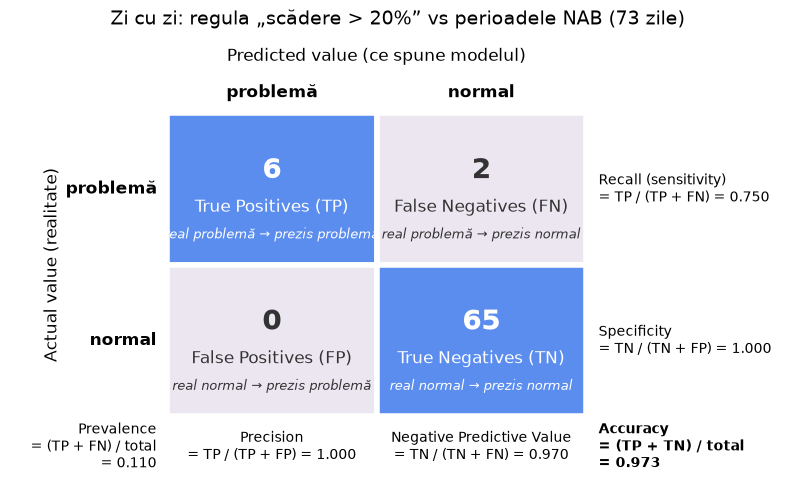

In [14]:
import numpy as np
# arrays
zile_judecate = diferenta_m.dropna().index
# the days that have a 7-day baseline (the first 7 cannot be judged)
y_real = np.array([any(pd.Timestamp(a) <= z <= pd.Timestamp(b) for a, b in reale) for z in zile_judecate]).astype(int)
# 1 = the day is inside a real failure period, 0 = a normal day
y_pred = (diferenta_m[zile_judecate] < -0.20).astype(int).values
# 1 = our rule flagged the day
matrice_confuzie_explicata(y_real, y_pred, pozitiv="problemă", negativ="normal",
                           titlu=f"Zi cu zi: regula „scădere > 20%” vs perioadele NAB ({len(y_real)} zile)")
# the day-level confusion matrix

**What this cell does:**
- Day by day on the **73 days** that have a baseline (80 minus the first 7). Positive = a day inside a NAB failure period (8 such days).
  - **TP 6, FN 2, FP 0, TN 65.**
  - recall **0.750**, specificity **1.000**, precision **1.000**, accuracy 0.973.
- The 2 FN are 11 and 17 Dec: the machine had recovered by then, so a daily-mean rule cannot see it. Per *period* the recall is 4/4.
- **Accuracy 0.973 says little here:** "always normal" would already reach 65/73 = 0.89, because only 11% of the days are positive (the prevalence). Recall and precision are the numbers that matter for alerts.

### Pasul 9 · Răspunde pe scurt

Scrie 2–3 rânduri pentru fiecare întrebare:

1. Câte din cele 4 perioade ai găsit?
2. Ce se întâmplă dacă pui pragul la 10%? Dar la 40%?
3. De ce am folosit aici ultimele 7 zile și nu aceeași zi de acum o săptămână, ca la taxiuri?
4. Dacă ai fi inginerul fabricii, ce ai face cu o alertă ca aceasta?

## Răspunsurile tale

> ✍️ Scrie aici răspunsurile tale.
>
> *(Answers based on the numbers in the extra cells below.)*
>
> **1. How many of the 4 periods did I find?** All **4 of 4**, with the 20% rule: 10 Dec, 16 Dec, 28 Jan and 7–9 Feb, and no false alarm. Only the second day of two periods (11 and 17 Dec) was not flagged, because the daily mean was already back to normal.
>
> **2. Threshold 10% or 40%?**
> - **10%:** 12 flagged days. Still 4 of 4 periods, but 6 false alarms.
> - **40%:** only 8 Feb, so only 1 of 4 periods.
>
> A lower threshold catches more and raises more false alarms; a higher one is quieter but misses failures. 20% was the sweet spot on this data.
>
> **3. Why the last 7 days and not the same day a week ago?** A factory machine has no weekly rhythm, unlike taxis (weekend vs weekday), so "the same weekday" brings no extra information. It also depends on **one** day: if that day was bad, the comparison is wrong. With it, 16 Dec is missed (3 of 4 periods) and 30 Jan becomes a false alarm. The **median of the 7 previous days** is a stable baseline that one bad day cannot drag down, and `shift(1)` keeps today out of its own baseline.
>
> **4. What would I do with such an alert as the plant engineer?** Treat it as "go and check", not as proof:
> - look at the 5-minute data for that day;
> - check whether the stop was planned (maintenance) or not;
> - inspect the machine.
>
> In production I would compute it every few hours instead of once per day, so the drop is seen while it is happening. I would also tune the threshold together with the cost of a missed failure vs a useless inspection.

## Recapitulare

O anomalie este ceva foarte diferit de normal. Pentru a găsi o problemă, mai întâi definim normalul, apoi măsurăm diferența și alegem un prag.

**Important:** o alertă nu dovedește automat că există o problemă. Ea spune doar că merită să verificăm ce s-a întâmplat.